In [1]:
import os
import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

PATCH_DIR = (
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/"
    "Dataset/GOES_TrainPatches_2048_NEW"
)

MANIFEST = os.path.join(PATCH_DIR, "train_patches.csv")
patch_df = pd.read_csv(MANIFEST)

print("Total patches:", len(patch_df))
print("Manifest columns:", patch_df.columns.tolist())

class GOESPatchDataset(Dataset):
    def __init__(self, dataframe, patch_size=2048):
        self.df = dataframe.reset_index(drop=True)
        self.patch_size = patch_size

    def __len__(self):
        return len(self.df)

    def load_image(self, path):
        arr = np.load(path).astype(np.float32)

        if arr.shape != (self.patch_size, self.patch_size):
            raise ValueError(
                f"Unexpected image shape {arr.shape}: {path}"
            )

        if not np.isfinite(arr).all():
            raise ValueError(f"Non-finite image values: {path}")

        # GOES data is grayscale. RIFE expects 3 channels per frame.
        tensor = torch.from_numpy(arr).unsqueeze(0)
        tensor = tensor.repeat(3, 1, 1)

        return tensor.contiguous()

    def load_mask(self, path):
        arr = np.load(path).astype(np.float32)

        if arr.shape != (self.patch_size, self.patch_size):
            raise ValueError(
                f"Unexpected mask shape {arr.shape}: {path}"
            )

        return torch.from_numpy(arr).unsqueeze(0).contiguous()

    def __getitem__(self, index):
        row = self.df.iloc[index]

        img0 = self.load_image(row["img0_path"])
        gt = self.load_image(row["gt_path"])
        img2 = self.load_image(row["img2_path"])

        mask0 = self.load_mask(row["mask0_path"])
        mask_gt = self.load_mask(row["mask_gt_path"])
        mask2 = self.load_mask(row["mask2_path"])

        return {
            "img0": img0,
            "gt": gt,
            "img2": img2,
            "mask0": mask0,
            "mask_gt": mask_gt,
            "mask2": mask2,
            "patch_id": row["patch_id"],
        }

train_dataset = GOESPatchDataset(patch_df, patch_size=2048)

print("Dataset created successfully.")
print("Dataset length:", len(train_dataset))

Total patches: 5067
Manifest columns: ['patch_id', 'img0_path', 'gt_path', 'img2_path', 'mask0_path', 'mask_gt_path', 'mask2_path', 'source_triplet_index', 'y', 'x', 'valid_ratio_img0', 'valid_ratio_gt', 'valid_ratio_img2']
Dataset created successfully.
Dataset length: 5067


In [2]:
train_loader = DataLoader(
    train_dataset,
    batch_size=1,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available(),
    drop_last=False
)

print("DataLoader created.")
print("Number of batches per epoch:", len(train_loader))

# Load one batch for testing
batch = next(iter(train_loader))

print("\nBatch verification:")
for key in ["img0", "gt", "img2", "mask0", "mask_gt", "mask2"]:
    print(
        f"{key:10s}",
        "shape =", tuple(batch[key].shape),
        "dtype =", batch[key].dtype
    )

# RIFE input: concatenate first and third frames
imgs = torch.cat(
    [batch["img0"], batch["img2"]],
    dim=1
)

gt = batch["gt"]

print("\nRIFE input shape:", tuple(imgs.shape))
print("Ground-truth shape:", tuple(gt.shape))

assert imgs.shape == (1, 6, 2048, 2048)
assert gt.shape == (1, 3, 2048, 2048)

print("\nBatch verification passed.")

DataLoader created.
Number of batches per epoch: 5067

Batch verification:
img0       shape = (1, 3, 2048, 2048) dtype = torch.float32
gt         shape = (1, 3, 2048, 2048) dtype = torch.float32
img2       shape = (1, 3, 2048, 2048) dtype = torch.float32
mask0      shape = (1, 1, 2048, 2048) dtype = torch.float32
mask_gt    shape = (1, 1, 2048, 2048) dtype = torch.float32
mask2      shape = (1, 1, 2048, 2048) dtype = torch.float32

RIFE input shape: (1, 6, 2048, 2048)
Ground-truth shape: (1, 3, 2048, 2048)

Batch verification passed.


In [3]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print(
        "GPU memory:",
        round(
            torch.cuda.get_device_properties(0).total_memory / (1024**3),
            2
        ),
        "GB"
    )
else:
    print("CUDA is unavailable. Do not start GPU training yet.")

PyTorch version: 2.13.0+cu130
CUDA available: True
GPU: NVIDIA H200 NVL
GPU memory: 139.8 GB


In [4]:
from pathlib import Path
import ast

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

matches = []

for py_file in PROJECT_DIR.rglob("*.py"):
    # Ignore common large or irrelevant directories
    if any(part in {
        ".git", "__pycache__", "venv", ".venv"
    } for part in py_file.parts):
        continue

    try:
        source = py_file.read_text(
            encoding="utf-8",
            errors="ignore"
        )
        tree = ast.parse(source)
    except Exception:
        continue

    for node in ast.walk(tree):
        if isinstance(node, (ast.FunctionDef, ast.AsyncFunctionDef)):
            if node.name == "update":
                matches.append((str(py_file), node.lineno))

print("Files containing an update() method:\n")

for file_path, line_no in matches:
    print(f"{file_path}  (line {line_no})")

if not matches:
    print(
        "\nNo update() method found. We need to inspect your RIFE "
        "training files before writing the training loop."
    )

Files containing an update() method:

/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM.py  (line 143)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/RIFE_CMAM_CMCL.py  (line 72)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/oldmodel/RIFE_HD.py  (line 215)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/oldmodel/RIFE_HDv2.py  (line 200)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE_CMAM_CMCL-checkpoint.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE-checkpoint.py  (line 70)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Research_RIFE/model/.ipynb_checkpoints/RIFE_CMAM-checkpoint.py  (line 143)
/home/kiruthigat.25mcse/Satellite_Frame_Interpolation/Official_RIFE/

In [5]:
import os
import sys
import csv
import time
from pathlib import Path

import torch
import pandas as pd
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RESEARCH_DIR = PROJECT_DIR / "Research_RIFE"

# Optional pretrained Base RIFE checkpoint
BASELINE_CKPT = PROJECT_DIR / "checkpoints" / "rife_goes_baseline.pth"

# Save the CMAM + CMCL experiment separately from Base RIFE
CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_CMAM_CMCL_2048"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
SAVE_EVERY_EPOCH = 1
LOG_EVERY_BATCHES = 50

DISTILL_WEIGHT = 0.01
CMCL_WEIGHT = 0.01

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

assert torch.cuda.is_available(), "CUDA GPU is unavailable."
assert len(train_dataset) > 0, "Training dataset is empty."

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("CMCL weight:", CMCL_WEIGHT)
print("Checkpoint directory:", CHECKPOINT_DIR)

GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067
Epochs: 100
Learning rate: 1e-06
CMCL weight: 0.01
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_2048


In [6]:
# ============================================================
# 2. IMPORT RIFE + CMAM + CMCL
# ============================================================

sys.path.insert(0, str(RESEARCH_DIR))

from model.RIFE_CMAM_CMCL import Model

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

# Move the network to GPU
model_cmcl.flownet = model_cmcl.flownet.to(device)

print("RIFE + CMAM + CMCL model initialized.")
print("Device:", device)

RIFE + CMAM + CMCL model initialized.
Device: cuda


In [7]:
import os
import sys
import csv
import time
import math
from pathlib import Path

import torch
import pandas as pd
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

RESEARCH_DIR = PROJECT_DIR / "Research_RIFE"

# New directory: does not reuse Base RIFE checkpoints
CHECKPOINT_DIR = (
    PROJECT_DIR / "checkpoints_NEW" / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
SAVE_EVERY_EPOCH = 1
LOG_EVERY_BATCHES = 50

DISTILL_WEIGHT = 0.01
CMCL_WEIGHT = 0.01

EPOCH_LOG = CHECKPOINT_DIR / "epoch_losses.csv"
BATCH_LOG = CHECKPOINT_DIR / "batch_losses.csv"

assert torch.cuda.is_available(), "CUDA GPU is unavailable."
assert len(train_dataset) > 0, "Training dataset is empty."

device = torch.device("cuda")

print("GPU:", torch.cuda.get_device_name(0))
print("Training patches:", len(train_dataset))
print("Batches per epoch:", len(train_loader))
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("CMCL weight:", CMCL_WEIGHT)
print("Checkpoint directory:", CHECKPOINT_DIR)

GPU: NVIDIA H200 NVL
Training patches: 5067
Batches per epoch: 5067
Epochs: 100
Learning rate: 1e-06
CMCL weight: 0.01
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH


In [8]:
# ============================================================
# 2. IMPORT MODEL
# ============================================================

sys.path.insert(0, str(RESEARCH_DIR))

from model.RIFE_CMAM_CMCL import Model

# Fresh model initialization.
# Do not load BASELINE_CKPT or any previous epoch checkpoint.
model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

model_cmcl.flownet = model_cmcl.flownet.to(device)

print("RIFE + CMAM + CMCL initialized from scratch.")
print("No baseline checkpoint loaded.")

RIFE + CMAM + CMCL initialized from scratch.
No baseline checkpoint loaded.


In [9]:
# ============================================================
# 3. FRESH TRAINING: NO RESUME
# ============================================================

start_epoch = 0

print("Starting epoch:", start_epoch + 1)
print("Training epochs:", EPOCHS)

assert start_epoch == 0

Starting epoch: 1
Training epochs: 100


In [9]:
# ============================================================
# RIFE + CMAM + CMCL — FRESH TRAINING
# No baseline checkpoint and no old epoch checkpoint loading
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. Project paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

LOG_DIR = CHECKPOINT_DIR / "logs"
LOG_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = LOG_DIR / "training_history.csv"

# ------------------------------------------------------------
# 2. Training configuration
# ------------------------------------------------------------

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("CMCL weight:", CMCL_WEIGHT)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 3. Initialize a completely new model
# ------------------------------------------------------------

from model.RIFE_CMAM_CMCL import Model

# IMPORTANT:
# Do not call load_model() or load an existing checkpoint.
# This assumes the Model constructor itself does not load
# pretrained weights internally.

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

print("New RIFE + CMAM + CMCL model initialized.")

# ------------------------------------------------------------
# 4. Validate existing training loader
# ------------------------------------------------------------

assert "train_loader" in globals(), (
    "train_loader is missing. Run your dataset and DataLoader cells first."
)

assert len(train_loader) > 0, (
    "train_loader is empty. Check your training CSV and patch files."
)

print("Training batches per epoch:", len(train_loader))

# ------------------------------------------------------------
# 5. Helper: convert input images to RGB
# ------------------------------------------------------------

def ensure_rgb(x):
    """
    Accepts [B, C, H, W].
    Converts grayscale images to 3 channels.
    """
    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(f"Unexpected image shape: {x.shape}")

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    elif x.shape[1] != 3:
        raise ValueError(
            f"Expected 1 or 3 channels, received {x.shape[1]}"
        )

    return x.float()

# ------------------------------------------------------------
# 6. Create a new history file
# ------------------------------------------------------------

# This is a fresh run: overwrite the old history file
# in this NEW experiment directory.

with open(HISTORY_CSV, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "epoch",
        "loss_l1",
        "loss_teacher",
        "loss_distill",
        "loss_cmcl",
        "loss_total_logged",
        "duration_seconds"
    ])

# ------------------------------------------------------------
# 7. Start from epoch 1
# ------------------------------------------------------------

start_epoch = 1

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    epoch_l1 = 0.0
    epoch_teacher = 0.0
    epoch_distill = 0.0
    epoch_cmcl = 0.0
    epoch_total = 0.0

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress, start=1):

        # ----------------------------------------------------
        # 7A. Read batch
        # Supports tuple/list or dictionary batches
        # ----------------------------------------------------

        if isinstance(batch, dict):
            img0 = batch["img0"]
            img2 = batch["img2"]
            gt = batch["gt"]

        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:
            img0, img2, gt = batch[:3]

        else:
            raise ValueError(
                "Unexpected batch format. Expected "
                "(img0, img2, gt) or a dictionary with those keys."
            )

        img0 = ensure_rgb(img0).to(device, non_blocking=True)
        img2 = ensure_rgb(img2).to(device, non_blocking=True)
        gt = ensure_rgb(gt).to(device, non_blocking=True)

        # ----------------------------------------------------
        # 7B. Prepare RIFE input
        # [B, 3, H, W] + [B, 3, H, W] -> [B, 6, H, W]
        # ----------------------------------------------------

        imgs = torch.cat([img0, img2], dim=1)

        if not (
            imgs.shape[0] == gt.shape[0]
            and imgs.shape[-2:] == gt.shape[-2:]
        ):
            raise ValueError(
                f"Input/target shape mismatch: "
                f"imgs={imgs.shape}, gt={gt.shape}"
            )

        # ----------------------------------------------------
        # 7C. Forward + optimization using custom Model.update
        # ----------------------------------------------------

        with torch.autograd.set_detect_anomaly(False):

            result = model_cmcl.update(
                imgs,
                gt,
                learning_rate=LEARNING_RATE,
                training=True
            )

        # Official RIFE wrappers commonly return (pred, info)
        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError(
                "model_cmcl.update() did not return (prediction, info). "
                "Check the custom Model.update implementation."
            )

        pred, info = result[0], result[1]

        # ----------------------------------------------------
        # 7D. Read training losses
        # ----------------------------------------------------

        if not isinstance(info, dict):
            raise RuntimeError(
                f"Expected info to be a dictionary; got {type(info)}"
            )

        required_keys = [
            "loss_l1",
            "loss_tea",
            "loss_distill",
            "loss_motion"
        ]

        missing = [k for k in required_keys if k not in info]

        if missing:
            raise KeyError(
                f"Missing losses in model.update() output: {missing}. "
                f"Available keys: {list(info.keys())}. "
                "Check RIFE_CMAM_CMCL.py before continuing."
            )

        loss_l1 = float(info["loss_l1"])
        loss_teacher = float(info["loss_tea"])
        loss_distill = float(info["loss_distill"])
        loss_cmcl = float(info["loss_motion"])

        # This is a logging value. The actual optimization objective
        # must be implemented inside Model.update().
        loss_total_logged = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
            + CMCL_WEIGHT * loss_cmcl
        )

        losses = [
            loss_l1,
            loss_teacher,
            loss_distill,
            loss_cmcl,
            loss_total_logged
        ]

        if not all(math.isfinite(v) for v in losses):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch}, "
                f"batch {batch_idx}: {losses}"
            )

        epoch_l1 += loss_l1
        epoch_teacher += loss_teacher
        epoch_distill += loss_distill
        epoch_cmcl += loss_cmcl
        epoch_total += loss_total_logged
        valid_batches += 1

        progress.set_postfix({
            "L1": f"{loss_l1:.5f}",
            "CMCL": f"{loss_cmcl:.5f}",
            "Total": f"{loss_total_logged:.5f}"
        })

        # Release references to batch tensors
        del imgs, img0, img2, gt, pred, result

    # --------------------------------------------------------
    # 8. Epoch summary
    # --------------------------------------------------------

    if valid_batches == 0:
        raise RuntimeError("No training batches were processed.")

    avg_l1 = epoch_l1 / valid_batches
    avg_teacher = epoch_teacher

Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Epochs: 100
Learning rate: 1e-06
CMCL weight: 0.01
GPU: NVIDIA H200 NVL
New RIFE + CMAM + CMCL model initialized.
Training batches per epoch: 5067


RIFE-CMAM-CMCL Epoch 1/100:   0%|          | 0/5067 [00:00<?, ?it/s]

/tmp/ipykernel_348994/2142361746.py:245: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:822.)
  loss_l1 = float(info["loss_l1"])


KeyboardInterrupt: 

In [ ]:

# ============================================================
# RIFE + CMAM + CMCL — FRESH TRAINING FROM SCRATCH
# Save checkpoint after EVERY completed epoch
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

LOG_DIR = CHECKPOINT_DIR / "logs"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

HISTORY_CSV = LOG_DIR / "training_history.csv"

# ------------------------------------------------------------
# 2. TRAINING CONFIGURATION
# ------------------------------------------------------------

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Epochs:", EPOCHS)
print("Learning rate:", LEARNING_RATE)
print("CMCL weight:", CMCL_WEIGHT)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# 3. INITIALIZE A NEW MODEL
# ------------------------------------------------------------

from model.RIFE_CMAM_CMCL import Model

# Fresh initialization: do not call load_model().
# Verify that the Model constructor does not load pretrained
# weights internally.

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

print("New RIFE + CMAM + CMCL model initialized.")

# ------------------------------------------------------------
# 4. VALIDATE TRAINING LOADER
# ------------------------------------------------------------

assert "train_loader" in globals(), (
    "Run the dataset and DataLoader initialization cells first."
)

assert len(train_loader) > 0, (
    "train_loader is empty. Check the training CSV and patches."
)

print("Training batches per epoch:", len(train_loader))

# ------------------------------------------------------------
# 5. CONVERT IMAGES TO RGB
# ------------------------------------------------------------

def ensure_rgb(x):

    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(
            f"Unexpected image shape: {tuple(x.shape)}"
        )

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)

    elif x.shape[1] != 3:
        raise ValueError(
            f"Expected 1 or 3 channels, got {x.shape[1]}"
        )

    return x.float()

# ------------------------------------------------------------
# 6. CHECKPOINT SAVING FUNCTION
# ------------------------------------------------------------

def save_epoch_checkpoint(model, epoch, metrics):

    checkpoint_path = (
        CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
    )

    # Locate the trainable network exposed by the custom wrapper.
    network = None

    if isinstance(model, torch.nn.Module):
        network = model
    else:
        for name in ("flownet", "network", "net", "model"):
            candidate = getattr(model, name, None)

            if isinstance(candidate, torch.nn.Module):
                network = candidate
                break

    # Collect optimizer states exposed directly by the wrapper.
    optimizer_states = {}

    for name, obj in vars(model).items():
        if isinstance(obj, torch.optim.Optimizer):
            optimizer_states[name] = obj.state_dict()

    # Use the wrapper's native checkpoint API when available.
    native_save = getattr(model, "save_model", None)

    if callable(native_save):
        native_save(str(CHECKPOINT_DIR), epoch)

    if network is None:
        if not callable(native_save):
            raise RuntimeError(
                "Cannot find the trainable network or save_model(). "
                "Inspect model/RIFE_CMAM_CMCL.py and update this "
                "function to match the actual Model implementation."
            )

        # Native model save was used. Save epoch metadata as well.
        torch.save(
            {
                "epoch": epoch,
                "metrics": metrics,
                "learning_rate": LEARNING_RATE,
                "cmcl_weight": CMCL_WEIGHT,
            },
            CHECKPOINT_DIR / f"epoch_{epoch:03d}_metadata.pth"
        )

    else:
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": network.state_dict(),
            "optimizer_states": optimizer_states,
            "metrics": metrics,
            "learning_rate": LEARNING_RATE,
            "cmcl_weight": CMCL_WEIGHT,
        }

        # Write a temporary file first, then replace the destination.
        # This reduces the chance of leaving a partially written file.
        temporary_path = CHECKPOINT_DIR / (
            f"epoch_{epoch:03d}.tmp"
        )

        try:
            torch.save(checkpoint, temporary_path)
            os.replace(temporary_path, checkpoint_path)
        finally:
            if temporary_path.exists():
                temporary_path.unlink()

    print(f"Checkpoint saved for epoch {epoch}.")

# ------------------------------------------------------------
# 7. CREATE FRESH TRAINING HISTORY
# ------------------------------------------------------------

# This intentionally starts a new run and overwrites the CSV.
# Existing checkpoint files are NOT deleted.

with open(HISTORY_CSV, "w", newline="") as f:
    writer = csv.writer(f)
    writer.writerow([
        "epoch",
        "loss_l1",
        "loss_teacher",
        "loss_distill",
        "loss_cmcl",
        "loss_total_logged",
        "duration_seconds",
    ])

print("History CSV:", HISTORY_CSV)

# ------------------------------------------------------------
# 8. START FRESH TRAINING FROM EPOCH 1
# ------------------------------------------------------------

start_epoch = 1

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    epoch_l1 = 0.0
    epoch_teacher = 0.0
    epoch_distill = 0.0
    epoch_cmcl = 0.0
    epoch_total = 0.0

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    # --------------------------------------------------------
    # 8A. TRAINING BATCHES
    # --------------------------------------------------------

    for batch_idx, batch in enumerate(progress, start=1):

        if isinstance(batch, dict):
            img0 = batch["img0"]
            img2 = batch["img2"]
            gt = batch["gt"]

        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:
            img0, img2, gt = batch[:3]

        else:
            raise ValueError(
                "Expected (img0, img2, gt) or a dictionary "
                "containing img0, img2, and gt."
            )

        img0 = ensure_rgb(img0).to(
            device, non_blocking=True
        )
        img2 = ensure_rgb(img2).to(
            device, non_blocking=True
        )
        gt = ensure_rgb(gt).to(
            device, non_blocking=True
        )

        # Two input frames: [B, 6, H, W]
        imgs = torch.cat([img0, img2], dim=1)

        if (
            imgs.shape[0] != gt.shape[0]
            or imgs.shape[-2:] != gt.shape[-2:]
        ):
            raise ValueError(
                f"Shape mismatch: imgs={imgs.shape}, gt={gt.shape}"
            )

        # ----------------------------------------------------
        # 8B. FORWARD PASS AND OPTIMIZATION
        # ----------------------------------------------------

        result = model_cmcl.update(
            imgs,
            gt,
            learning_rate=LEARNING_RATE,
            training=True
        )

        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError(
                "Expected model.update() to return (prediction, info)."
            )

        pred, info = result[0], result[1]

        if not isinstance(info, dict):
            raise RuntimeError(
                f"Expected info dictionary; got {type(info)}"
            )

        required_keys = [
            "loss_l1",
            "loss_tea",
            "loss_distill",
            "loss_motion",
        ]

        missing = [k for k in required_keys if k not in info]

        if missing:
            raise KeyError(
                f"Missing losses: {missing}. "
                f"Available keys: {list(info.keys())}"
            )

        def scalar_value(value):
            if torch.is_tensor(value):
                if value.numel() != 1:
                    raise ValueError("Expected scalar loss.")
                return value.detach().item()
            return float(value)

        loss_l1 = scalar_value(info["loss_l1"])
        loss_teacher = scalar_value(info["loss_tea"])
        loss_distill = scalar_value(info["loss_distill"])
        loss_cmcl = scalar_value(info["loss_motion"])

        # Logging only. Actual optimization is performed inside update().
        loss_total_logged = (
            loss_l1
            + loss_teacher
            + 0.01 * loss_distill
            + CMCL_WEIGHT * loss_cmcl
        )

        losses = [
            loss_l1,
            loss_teacher,
            loss_distill,
            loss_cmcl,
            loss_total_logged,
        ]

        if not all(math.isfinite(v) for v in losses):
            raise FloatingPointError(
                f"Invalid loss at epoch {epoch}, "
                f"batch {batch_idx}: {losses}"
            )

        epoch_l1 += loss_l1
        epoch_teacher += loss_teacher
        epoch_distill += loss_distill
        epoch_cmcl += loss_cmcl
        epoch_total += loss_total_logged

        valid_batches += 1

        progress.set_postfix({
            "L1": f"{loss_l1:.5f}",
            "CMCL": f"{loss_cmcl:.5f}",
            "Total": f"{loss_total_logged:.5f}",
        })

        del imgs, img0, img2, gt, pred, result

    # --------------------------------------------------------
    # 9. CALCULATE EPOCH AVERAGES
    # --------------------------------------------------------

    if valid_batches == 0:
        raise RuntimeError("No training batches were processed.")

    avg_l1 = epoch_l1 / valid_batches
    avg_teacher = epoch_teacher / valid_batches
    avg_distill = epoch_distill / valid_batches
    avg_cmcl = epoch_cmcl / valid_batches
    avg_total = epoch_total / valid_batches

    duration = time.time() - start_time

    metrics = {
        "loss_l1": avg_l1,
        "loss_teacher": avg_teacher,
        "loss_distill": avg_distill,
        "loss_cmcl": avg_cmcl,
        "loss_total_logged": avg_total,
        "duration_seconds": duration,
    }

    # --------------------------------------------------------
    # 10. PRINT SUMMARY
    # --------------------------------------------------------

    print("\n" + "=" * 60)
    print(f"EPOCH {epoch}/{EPOCHS} COMPLETED")
    print("=" * 60)

    print(f"L1 loss:       {avg_l1:.6f}")
    print(f"Teacher loss:  {avg_teacher:.6f}")
    print(f"Distill loss:  {avg_distill:.6f}")
    print(f"CMCL loss:     {avg_cmcl:.6f}")
    print(f"Total logged:  {avg_total:.6f}")
    print(f"Duration:      {duration:.2f} seconds")

    # --------------------------------------------------------
    # 11. SAVE HISTORY AFTER EACH EPOCH
    # --------------------------------------------------------

    with open(HISTORY_CSV, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch,
            avg_l1,
            avg_teacher,
            avg_distill,
            avg_cmcl,
            avg_total,
            duration,
        ])

    # --------------------------------------------------------
    # 12. SAVE CHECKPOINT AFTER EACH EPOCH
    # --------------------------------------------------------

    if epoch % SAVE_EVERY_EPOCH == 0:
        save_epoch_checkpoint(
            model=model_cmcl,
            epoch=epoch,
            metrics=metrics,
        )

    print(f"Epoch {epoch} finished and saved.")

# ------------------------------------------------------------
# 13. TRAINING COMPLETED
# ------------------------------------------------------------

print("\nTRAINING COMPLETED.")
print("Checkpoints:", CHECKPOINT_DIR)
print("Training history:", HISTORY_CSV)


Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Epochs: 100
Learning rate: 1e-06
CMCL weight: 0.01
GPU: NVIDIA H200 NVL
New RIFE + CMAM + CMCL model initialized.
Training batches per epoch: 5067
History CSV: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/logs/training_history.csv


RIFE-CMAM-CMCL Epoch 1/100:   0%|          | 0/5067 [00:00<?, ?it/s]


EPOCH 1/100 COMPLETED
L1 loss:       0.020812
Teacher loss:  0.020570
Distill loss:  0.002782
CMCL loss:     0.017597
Total logged:  0.041586
Duration:      8445.35 seconds
Checkpoint saved for epoch 1.
Epoch 1 finished and saved.


RIFE-CMAM-CMCL Epoch 2/100:   0%|          | 0/5067 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [ ]:

# ============================================================
# RIFE + CMAM + CMCL — RESUME TRAINING FROM EPOCH 2
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

LOG_DIR = CHECKPOINT_DIR / "logs"
HISTORY_CSV = LOG_DIR / "training_history.csv"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
DISTILL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)

from model.RIFE_CMAM_CMCL import Model

# Initialize the model architecture.
model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

# ------------------------------------------------------------
# 1. LOAD THE COMPLETED EPOCH 1 CHECKPOINT
# ------------------------------------------------------------

checkpoint_path = CHECKPOINT_DIR / "epoch_001.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Epoch 1 checkpoint not found: {checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if "model_state_dict" not in checkpoint:
    raise RuntimeError(
        "This checkpoint does not contain model_state_dict. "
        "Inspect the checkpoint format and use the custom "
        "model's native loading method if required."
    )

# Locate the actual trainable network.
network = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)
        if isinstance(candidate, torch.nn.Module):
            network = candidate
            break

if network is None:
    raise RuntimeError(
        "Could not locate the trainable network in Model."
    )

network.load_state_dict(checkpoint["model_state_dict"])

# Restore optimizer state if it was saved.
optimizer_states = checkpoint.get("optimizer_states", {})

if optimizer_states:
    restored_optimizers = 0

    for name, state in optimizer_states.items():
        optimizer = getattr(model_cmcl, name, None)

        if isinstance(optimizer, torch.optim.Optimizer):
            optimizer.load_state_dict(state)
            restored_optimizers += 1

    print("Optimizer states restored:", restored_optimizers)
else:
    print(
        "WARNING: No optimizer state was saved. "
        "Training can continue, but optimizer progress will not "
        "be restored exactly."
    )

completed_epoch = int(checkpoint.get("epoch", 1))
start_epoch = completed_epoch + 1

print("Completed epoch:", completed_epoch)
print("Next epoch:", start_epoch)

if start_epoch > EPOCHS:
    raise RuntimeError("Training has already reached the target epoch.")

# ------------------------------------------------------------
# 2. RESTORE OR CREATE THE TRAINING HISTORY
# ------------------------------------------------------------

if not HISTORY_CSV.exists():
    with open(HISTORY_CSV, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "epoch",
            "loss_l1",
            "loss_teacher",
            "loss_distill",
            "loss_cmcl",
            "loss_total_logged",
            "duration_seconds"
        ])

# ------------------------------------------------------------
# 3. IMAGE PREPARATION
# ------------------------------------------------------------

def ensure_rgb(x):
    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(f"Unexpected image shape: {x.shape}")

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    elif x.shape[1] != 3:
        raise ValueError(f"Unexpected channel count: {x.shape[1]}")

    return x.float()

assert "train_loader" in globals(), (
    "Initialize train_loader before running this cell."
)
assert len(train_loader) > 0, "train_loader is empty."

# ------------------------------------------------------------
# 4. SAVE FUNCTION FOR FUTURE EPOCHS
# ------------------------------------------------------------

def save_checkpoint(epoch, metrics):
    path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"

    optimizer_states = {
        name: obj.state_dict()
        for name, obj in vars(model_cmcl).items()
        if isinstance(obj, torch.optim.Optimizer)
    }

    data = {
        "epoch": epoch,
        "model_state_dict": network.state_dict(),
        "optimizer_states": optimizer_states,
        "metrics": metrics,
        "learning_rate": LEARNING_RATE,
        "cmcl_weight": CMCL_WEIGHT,
    }

    temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.tmp"

    try:
        torch.save(data, temp_path)
        os.replace(temp_path, path)
    finally:
        if temp_path.exists():
            temp_path.unlink()

    print("Saved:", path)

# ------------------------------------------------------------
# 5. RESUME TRAINING FROM EPOCH 2
# ------------------------------------------------------------

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    sums = {
        "loss_l1": 0.0,
        "loss_teacher": 0.0,
        "loss_distill": 0.0,
        "loss_cmcl": 0.0,
        "loss_total_logged": 0.0,
    }

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress, start=1):

        if isinstance(batch, dict):
            img0, img2, gt = (
                batch["img0"], batch["img2"], batch["gt"]
            )
        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:
            img0, img2, gt = batch[:3]
        else:
            raise ValueError("Unexpected training batch format.")

        img0 = ensure_rgb(img0).to(device, non_blocking=True)
        img2 = ensure_rgb(img2).to(device, non_blocking=True)
        gt = ensure_rgb(gt).to(device, non_blocking=True)

        imgs = torch.cat([img0, img2], dim=1)

        result = model_cmcl.update(
            imgs,
            gt,
            learning_rate=LEARNING_RATE,
            training=True
        )

        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError("Expected (prediction, info) from update().")

        pred, info = result[0], result[1]

        required = [
            "loss_l1", "loss_tea", "loss_distill", "loss_motion"
        ]
        missing = [key for key in required if key not in info]

        if missing:
            raise KeyError(f"Missing loss keys: {missing}")

        values = {
            "loss_l1": float(
                torch.as_tensor(info["loss_l1"]).detach().item()
            ),
            "loss_teacher": float(
                torch.as_tensor(info["loss_tea"]).detach().item()
            ),
            "loss_distill": float(
                torch.as_tensor(info["loss_distill"]).detach().item()
            ),
            "loss_cmcl": float(
                torch.as_tensor(info["loss_motion"]).detach().item()
            ),
        }

        values["loss_total_logged"] = (
            values["loss_l1"]
            + values["loss_teacher"]
            + DISTILL_WEIGHT * values["loss_distill"]
            + CMCL_WEIGHT * values["loss_cmcl"]
        )

        if not all(math.isfinite(v) for v in values.values()):
            raise FloatingPointError(
                f"Invalid loss at epoch {epoch}, batch {batch_idx}"
            )

        for key, value in values.items():
            sums[key] += value

        valid_batches += 1

        progress.set_postfix({
            "L1": f'{values["loss_l1"]:.5f}',
            "CMCL": f'{values["loss_cmcl"]:.5f}',
            "Total": f'{values["loss_total_logged"]:.5f}',
        })

        del imgs, img0, img2, gt, pred, result

    if valid_batches == 0:
        raise RuntimeError("No training batches were processed.")

    averages = {
        key: value / valid_batches
        for key, value in sums.items()
    }

    duration = time.time() - start_time

    metrics = {
        **averages,
        "duration_seconds": duration,
    }

    print(f"\nEpoch {epoch}/{EPOCHS} completed.")
    for key, value in averages.items():
        print(f"{key}: {value:.6f}")
    print(f"Duration: {duration:.2f} seconds")

    # Append history; do not erase earlier epochs.
    with open(HISTORY_CSV, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch,
            averages["loss_l1"],
            averages["loss_teacher"],
            averages["loss_distill"],
            averages["loss_cmcl"],
            averages["loss_total_logged"],
            duration,
        ])

    if epoch % SAVE_EVERY_EPOCH == 0:
        save_checkpoint(epoch, metrics)

print("Training completed.")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("History CSV:", HISTORY_CSV)


Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Optimizer states restored: 1
Completed epoch: 1
Next epoch: 2


RIFE-CMAM-CMCL Epoch 2/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 2/100 completed.
loss_l1: 0.020101
loss_teacher: 0.020088
loss_distill: 0.002225
loss_cmcl: 0.016531
loss_total_logged: 0.040377
Duration: 8266.28 seconds
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_002.pth


RIFE-CMAM-CMCL Epoch 3/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 3/100 completed.
loss_l1: 0.019610
loss_teacher: 0.019727
loss_distill: 0.012701
loss_cmcl: 0.016464
loss_total_logged: 0.039629
Duration: 7942.60 seconds
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_003.pth


RIFE-CMAM-CMCL Epoch 4/100:   0%|          | 0/5067 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)




Epoch 4/100 completed.
loss_l1: 0.018888
loss_teacher: 0.019085
loss_distill: 0.037700
loss_cmcl: 0.016346
loss_total_logged: 0.038513
Duration: 7932.59 seconds
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_004.pth


RIFE-CMAM-CMCL Epoch 5/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 5/100 completed.
loss_l1: 0.017551
loss_teacher: 0.017710
loss_distill: 0.050062
loss_cmcl: 0.015909
loss_total_logged: 0.035921
Duration: 7806.96 seconds
Saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_005.pth


RIFE-CMAM-CMCL Epoch 6/100:   0%|          | 0/5067 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# RIFE + CMAM + CMCL — RESUME TRAINING FROM EPOCH 6
# Loads epoch_005.pth and continues from epoch 6
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

LOG_DIR = CHECKPOINT_DIR / "logs"
HISTORY_CSV = LOG_DIR / "training_history.csv"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
DISTILL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)

# ============================================================
# 2. INITIALIZE MODEL
# ============================================================

from model.RIFE_CMAM_CMCL import Model

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

# ============================================================
# 3. LOAD EPOCH 5 CHECKPOINT
# ============================================================

checkpoint_path = CHECKPOINT_DIR / "epoch_005.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Epoch 5 checkpoint not found:\n{checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Checkpoint is not a dictionary.")

if "model_state_dict" not in checkpoint:
    raise RuntimeError(
        "The checkpoint does not contain 'model_state_dict'. "
        "Inspect its format before continuing."
    )

# Locate the actual trainable network.
network = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)

        if isinstance(candidate, torch.nn.Module):
            network = candidate
            break

if network is None:
    raise RuntimeError(
        "Could not locate the trainable network. "
        "Check the Model class in RIFE_CMAM_CMCL.py."
    )

# Restore model weights.
network.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("Model weights restored from epoch 5.")

# ============================================================
# 4. RESTORE OPTIMIZER STATES
# ============================================================

optimizer_states = checkpoint.get("optimizer_states", {})
restored_optimizers = 0

if optimizer_states:
    for name, state in optimizer_states.items():
        optimizer = getattr(model_cmcl, name, None)

        if isinstance(optimizer, torch.optim.Optimizer):
            optimizer.load_state_dict(state)
            restored_optimizers += 1

    print("Optimizer states restored:", restored_optimizers)

    if restored_optimizers == 0:
        print(
            "WARNING: No matching optimizer attributes were found. "
            "Model weights are restored, but optimizer states "
            "were not restored."
        )
else:
    print(
        "WARNING: The checkpoint contains no optimizer states. "
        "Training will continue without restoring optimizer progress."
    )

# Continue with the epoch after the checkpoint.
completed_epoch = int(checkpoint.get("epoch", 5))

if completed_epoch != 5:
    raise RuntimeError(
        f"Expected epoch 5 checkpoint, but it reports "
        f"epoch {completed_epoch}. Check the checkpoint file."
    )

start_epoch = completed_epoch + 1

print("Completed epoch:", completed_epoch)
print("Resuming from epoch:", start_epoch)
print("Final target epoch:", EPOCHS)

if start_epoch > EPOCHS:
    raise RuntimeError(
        "The checkpoint has already reached the target epoch."
    )

del checkpoint

# ============================================================
# 5. RESTORE OR CREATE TRAINING HISTORY
# ============================================================

if not HISTORY_CSV.exists():
    with open(HISTORY_CSV, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "epoch",
            "loss_l1",
            "loss_teacher",
            "loss_distill",
            "loss_cmcl",
            "loss_total_logged",
            "duration_seconds"
        ])

# ============================================================
# 6. IMAGE PREPARATION
# ============================================================

assert "train_loader" in globals(), (
    "Initialize train_loader before running this cell."
)

assert len(train_loader) > 0, "train_loader is empty."


def ensure_rgb(x):
    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(
            f"Unexpected image shape: {tuple(x.shape)}"
        )

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    elif x.shape[1] != 3:
        raise ValueError(
            f"Unexpected channel count: {x.shape[1]}"
        )

    return x.float()


# ============================================================
# 7. SAVE CHECKPOINT AFTER EACH EPOCH
# ============================================================

def save_checkpoint(epoch, metrics):

    path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
    temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.tmp"

    optimizer_states = {
        name: obj.state_dict()
        for name, obj in vars(model_cmcl).items()
        if isinstance(obj, torch.optim.Optimizer)
    }

    data = {
        "epoch": epoch,
        "model_state_dict": network.state_dict(),
        "optimizer_states": optimizer_states,
        "metrics": metrics,
        "learning_rate": LEARNING_RATE,
        "cmcl_weight": CMCL_WEIGHT,
        "distill_weight": DISTILL_WEIGHT,
    }

    try:
        torch.save(data, temp_path)
        os.replace(temp_path, path)
    finally:
        if temp_path.exists():
            temp_path.unlink()

    print("Checkpoint saved:", path)


# ============================================================
# 8. RESUME TRAINING FROM EPOCH 6
# ============================================================

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    sums = {
        "loss_l1": 0.0,
        "loss_teacher": 0.0,
        "loss_distill": 0.0,
        "loss_cmcl": 0.0,
        "loss_total_logged": 0.0,
    }

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress, start=1):

        # -------------------------------
        # Extract images
        # -------------------------------
        if isinstance(batch, dict):

            img0 = batch["img0"]
            img2 = batch["img2"]
            gt = batch["gt"]

        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:

            img0, img2, gt = batch[:3]

        else:
            raise ValueError(
                "Unexpected training batch format."
            )

        # -------------------------------
        # Prepare tensors
        # -------------------------------
        img0 = ensure_rgb(img0).to(
            device, non_blocking=True
        )

        img2 = ensure_rgb(img2).to(
            device, non_blocking=True
        )

        gt = ensure_rgb(gt).to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # -------------------------------
        # RIFE + CMAM + CMCL update
        # -------------------------------
        result = model_cmcl.update(
            imgs,
            gt,
            learning_rate=LEARNING_RATE,
            training=True
        )

        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError(
                "Expected (prediction, info) from model.update()."
            )

        pred, info = result[0], result[1]

        required_keys = [
            "loss_l1",
            "loss_tea",
            "loss_distill",
            "loss_motion",
        ]

        missing = [
            key for key in required_keys
            if key not in info
        ]

        if missing:
            raise KeyError(
                f"Missing loss keys in update(): {missing}"
            )

        # -------------------------------
        # Read loss values
        # -------------------------------
        values = {
            "loss_l1": float(
                torch.as_tensor(info["loss_l1"])
                .detach().item()
            ),
            "loss_teacher": float(
                torch.as_tensor(info["loss_tea"])
                .detach().item()
            ),
            "loss_distill": float(
                torch.as_tensor(info["loss_distill"])
                .detach().item()
            ),
            "loss_cmcl": float(
                torch.as_tensor(info["loss_motion"])
                .detach().item()
            ),
        }

        values["loss_total_logged"] = (
            values["loss_l1"]
            + values["loss_teacher"]
            + DISTILL_WEIGHT * values["loss_distill"]
            + CMCL_WEIGHT * values["loss_cmcl"]
        )

        if not all(
            math.isfinite(value)
            for value in values.values()
        ):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch}, "
                f"batch {batch_idx}: {values}"
            )

        for key, value in values.items():
            sums[key] += value

        valid_batches += 1

        progress.set_postfix({
            "L1": f'{values["loss_l1"]:.5f}',
            "CMCL": f'{values["loss_cmcl"]:.5f}',
            "Total": f'{values["loss_total_logged"]:.5f}',
        })

        del imgs, img0, img2, gt, pred, result

    if valid_batches == 0:
        raise RuntimeError(
            f"No training batches processed in epoch {epoch}."
        )

    # -------------------------------
    # Calculate epoch averages
    # -------------------------------
    averages = {
        key: value / valid_batches
        for key, value in sums.items()
    }

    duration = time.time() - start_time

    metrics = {
        **averages,
        "duration_seconds": duration,
    }

    print(f"\nEpoch {epoch}/{EPOCHS} completed.")

    for key, value in averages.items():
        print(f"{key}: {value:.6f}")

    print(f"Duration: {duration:.2f} seconds")

    # -------------------------------
    # Append training history
    # -------------------------------
    with open(HISTORY_CSV, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch,
            averages["loss_l1"],
            averages["loss_teacher"],
            averages["loss_distill"],
            averages["loss_cmcl"],
            averages["loss_total_logged"],
            duration,
        ])

    # -------------------------------
    # Save checkpoint
    # -------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:
        save_checkpoint(epoch, metrics)

print("\nTraining completed.")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Training history:", HISTORY_CSV)

Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Model weights restored from epoch 5.
Optimizer states restored: 1
Completed epoch: 5
Resuming from epoch: 6
Final target epoch: 100


RIFE-CMAM-CMCL Epoch 6/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 6/100 completed.
loss_l1: 0.016930
loss_teacher: 0.017093
loss_distill: 0.025223
loss_cmcl: 0.015689
loss_total_logged: 0.034432
Duration: 5052.30 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_006.pth


RIFE-CMAM-CMCL Epoch 7/100:   0%|          | 0/5067 [00:00<?, ?it/s]

In [ ]:
# ============================================================
# RIFE + CMAM + CMCL — RESUME TRAINING FROM EPOCH 6
# Loads epoch_005.pth and continues from epoch 6
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

LOG_DIR = CHECKPOINT_DIR / "logs"
HISTORY_CSV = LOG_DIR / "training_history.csv"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
DISTILL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)

# ============================================================
# 2. INITIALIZE MODEL
# ============================================================

from model.RIFE_CMAM_CMCL import Model

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

# ============================================================
# 3. LOAD EPOCH 5 CHECKPOINT
# ============================================================

checkpoint_path = CHECKPOINT_DIR / "epoch_006.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Epoch 6 checkpoint not found:\n{checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Checkpoint is not a dictionary.")

if "model_state_dict" not in checkpoint:
    raise RuntimeError(
        "The checkpoint does not contain 'model_state_dict'. "
        "Inspect its format before continuing."
    )

# Locate the actual trainable network.
network = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)

        if isinstance(candidate, torch.nn.Module):
            network = candidate
            break

if network is None:
    raise RuntimeError(
        "Could not locate the trainable network. "
        "Check the Model class in RIFE_CMAM_CMCL.py."
    )

# Restore model weights.
network.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("Model weights restored from epoch 5.")

# ============================================================
# 4. RESTORE OPTIMIZER STATES
# ============================================================

optimizer_states = checkpoint.get("optimizer_states", {})
restored_optimizers = 0

if optimizer_states:
    for name, state in optimizer_states.items():
        optimizer = getattr(model_cmcl, name, None)

        if isinstance(optimizer, torch.optim.Optimizer):
            optimizer.load_state_dict(state)
            restored_optimizers += 1

    print("Optimizer states restored:", restored_optimizers)

    if restored_optimizers == 0:
        print(
            "WARNING: No matching optimizer attributes were found. "
            "Model weights are restored, but optimizer states "
            "were not restored."
        )
else:
    print(
        "WARNING: The checkpoint contains no optimizer states. "
        "Training will continue without restoring optimizer progress."
    )

# Continue with the epoch after the checkpoint.
completed_epoch = int(checkpoint.get("epoch", 6))

if completed_epoch != 6:
    raise RuntimeError(
        f"Expected epoch 6 checkpoint, but it reports "
        f"epoch {completed_epoch}. Check the checkpoint file."
    )

start_epoch = completed_epoch + 1

print("Completed epoch:", completed_epoch)
print("Resuming from epoch:", start_epoch)
print("Final target epoch:", EPOCHS)

if start_epoch > EPOCHS:
    raise RuntimeError(
        "The checkpoint has already reached the target epoch."
    )

del checkpoint

# ============================================================
# 5. RESTORE OR CREATE TRAINING HISTORY
# ============================================================

if not HISTORY_CSV.exists():
    with open(HISTORY_CSV, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "epoch",
            "loss_l1",
            "loss_teacher",
            "loss_distill",
            "loss_cmcl",
            "loss_total_logged",
            "duration_seconds"
        ])

# ============================================================
# 6. IMAGE PREPARATION
# ============================================================

assert "train_loader" in globals(), (
    "Initialize train_loader before running this cell."
)

assert len(train_loader) > 0, "train_loader is empty."


def ensure_rgb(x):
    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(
            f"Unexpected image shape: {tuple(x.shape)}"
        )

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    elif x.shape[1] != 3:
        raise ValueError(
            f"Unexpected channel count: {x.shape[1]}"
        )

    return x.float()


# ============================================================
# 7. SAVE CHECKPOINT AFTER EACH EPOCH
# ============================================================

def save_checkpoint(epoch, metrics):

    path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
    temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.tmp"

    optimizer_states = {
        name: obj.state_dict()
        for name, obj in vars(model_cmcl).items()
        if isinstance(obj, torch.optim.Optimizer)
    }

    data = {
        "epoch": epoch,
        "model_state_dict": network.state_dict(),
        "optimizer_states": optimizer_states,
        "metrics": metrics,
        "learning_rate": LEARNING_RATE,
        "cmcl_weight": CMCL_WEIGHT,
        "distill_weight": DISTILL_WEIGHT,
    }

    try:
        torch.save(data, temp_path)
        os.replace(temp_path, path)
    finally:
        if temp_path.exists():
            temp_path.unlink()

    print("Checkpoint saved:", path)


# ============================================================
# 8. RESUME TRAINING FROM EPOCH 6
# ============================================================

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    sums = {
        "loss_l1": 0.0,
        "loss_teacher": 0.0,
        "loss_distill": 0.0,
        "loss_cmcl": 0.0,
        "loss_total_logged": 0.0,
    }

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress, start=1):

        # -------------------------------
        # Extract images
        # -------------------------------
        if isinstance(batch, dict):

            img0 = batch["img0"]
            img2 = batch["img2"]
            gt = batch["gt"]

        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:

            img0, img2, gt = batch[:3]

        else:
            raise ValueError(
                "Unexpected training batch format."
            )

        # -------------------------------
        # Prepare tensors
        # -------------------------------
        img0 = ensure_rgb(img0).to(
            device, non_blocking=True
        )

        img2 = ensure_rgb(img2).to(
            device, non_blocking=True
        )

        gt = ensure_rgb(gt).to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # -------------------------------
        # RIFE + CMAM + CMCL update
        # -------------------------------
        result = model_cmcl.update(
            imgs,
            gt,
            learning_rate=LEARNING_RATE,
            training=True
        )

        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError(
                "Expected (prediction, info) from model.update()."
            )

        pred, info = result[0], result[1]

        required_keys = [
            "loss_l1",
            "loss_tea",
            "loss_distill",
            "loss_motion",
        ]

        missing = [
            key for key in required_keys
            if key not in info
        ]

        if missing:
            raise KeyError(
                f"Missing loss keys in update(): {missing}"
            )

        # -------------------------------
        # Read loss values
        # -------------------------------
        values = {
            "loss_l1": float(
                torch.as_tensor(info["loss_l1"])
                .detach().item()
            ),
            "loss_teacher": float(
                torch.as_tensor(info["loss_tea"])
                .detach().item()
            ),
            "loss_distill": float(
                torch.as_tensor(info["loss_distill"])
                .detach().item()
            ),
            "loss_cmcl": float(
                torch.as_tensor(info["loss_motion"])
                .detach().item()
            ),
        }

        values["loss_total_logged"] = (
            values["loss_l1"]
            + values["loss_teacher"]
            + DISTILL_WEIGHT * values["loss_distill"]
            + CMCL_WEIGHT * values["loss_cmcl"]
        )

        if not all(
            math.isfinite(value)
            for value in values.values()
        ):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch}, "
                f"batch {batch_idx}: {values}"
            )

        for key, value in values.items():
            sums[key] += value

        valid_batches += 1

        progress.set_postfix({
            "L1": f'{values["loss_l1"]:.5f}',
            "CMCL": f'{values["loss_cmcl"]:.5f}',
            "Total": f'{values["loss_total_logged"]:.5f}',
        })

        del imgs, img0, img2, gt, pred, result

    if valid_batches == 0:
        raise RuntimeError(
            f"No training batches processed in epoch {epoch}."
        )

    # -------------------------------
    # Calculate epoch averages
    # -------------------------------
    averages = {
        key: value / valid_batches
        for key, value in sums.items()
    }

    duration = time.time() - start_time

    metrics = {
        **averages,
        "duration_seconds": duration,
    }

    print(f"\nEpoch {epoch}/{EPOCHS} completed.")

    for key, value in averages.items():
        print(f"{key}: {value:.6f}")

    print(f"Duration: {duration:.2f} seconds")

    # -------------------------------
    # Append training history
    # -------------------------------
    with open(HISTORY_CSV, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch,
            averages["loss_l1"],
            averages["loss_teacher"],
            averages["loss_distill"],
            averages["loss_cmcl"],
            averages["loss_total_logged"],
            duration,
        ])

    # -------------------------------
    # Save checkpoint
    # -------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:
        save_checkpoint(epoch, metrics)

print("\nTraining completed.")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Training history:", HISTORY_CSV)

Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Model weights restored from epoch 5.
Optimizer states restored: 1
Completed epoch: 6
Resuming from epoch: 7
Final target epoch: 100


RIFE-CMAM-CMCL Epoch 7/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 7/100 completed.
loss_l1: 0.016667
loss_teacher: 0.016846
loss_distill: 0.011860
loss_cmcl: 0.015571
loss_total_logged: 0.033788
Duration: 7792.88 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_007.pth


RIFE-CMAM-CMCL Epoch 8/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 8/100 completed.
loss_l1: 0.016493
loss_teacher: 0.016689
loss_distill: 0.009407
loss_cmcl: 0.015485
loss_total_logged: 0.033431
Duration: 6767.33 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_008.pth


RIFE-CMAM-CMCL Epoch 9/100:   0%|          | 0/5067 [00:00<?, ?it/s]

In [10]:
# ============================================================
# RIFE + CMAM + CMCL — RESUME TRAINING FROM EPOCH 90
# Loads epoch_090h and continues from epoch 91
# ============================================================

import os
import time
import csv
import math
import torch
from pathlib import Path
from tqdm.auto import tqdm

# ============================================================
# 1. CONFIGURATION
# ============================================================

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

LOG_DIR = CHECKPOINT_DIR / "logs"
HISTORY_CSV = LOG_DIR / "training_history.csv"

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
LOG_DIR.mkdir(parents=True, exist_ok=True)

EPOCHS = 100
LEARNING_RATE = 1e-6
CMCL_WEIGHT = 0.01
DISTILL_WEIGHT = 0.01
SAVE_EVERY_EPOCH = 1

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Checkpoint directory:", CHECKPOINT_DIR)

# ============================================================
# 2. INITIALIZE MODEL
# ============================================================

from model.RIFE_CMAM_CMCL import Model

model_cmcl = Model(
    local_rank=-1,
    arbitrary=False,
    cmcl_weight=CMCL_WEIGHT
)

# ============================================================
# 3. LOAD EPOCH 55 CHECKPOINT
# ============================================================

checkpoint_path = CHECKPOINT_DIR / "epoch_090.pth"

if not checkpoint_path.exists():
    raise FileNotFoundError(
        f"Epoch 90 checkpoint not found:\n{checkpoint_path}"
    )

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=False
)

if not isinstance(checkpoint, dict):
    raise RuntimeError("Checkpoint is not a dictionary.")

if "model_state_dict" not in checkpoint:
    raise RuntimeError(
        "The checkpoint does not contain 'model_state_dict'. "
        "Inspect its format before continuing."
    )

# Locate the actual trainable network.
network = None

if isinstance(model_cmcl, torch.nn.Module):
    network = model_cmcl
else:
    for name in ("flownet", "network", "net", "model"):
        candidate = getattr(model_cmcl, name, None)

        if isinstance(candidate, torch.nn.Module):
            network = candidate
            break

if network is None:
    raise RuntimeError(
        "Could not locate the trainable network. "
        "Check the Model class in RIFE_CMAM_CMCL.py."
    )

# Restore model weights.
network.load_state_dict(
    checkpoint["model_state_dict"],
    strict=True
)

print("Model weights restored from epoch 90.")

# ============================================================
# 4. RESTORE OPTIMIZER STATES
# ============================================================

optimizer_states = checkpoint.get("optimizer_states", {})
restored_optimizers = 0

if optimizer_states:
    for name, state in optimizer_states.items():
        optimizer = getattr(model_cmcl, name, None)

        if isinstance(optimizer, torch.optim.Optimizer):
            optimizer.load_state_dict(state)
            restored_optimizers += 1

    print("Optimizer states restored:", restored_optimizers)

    if restored_optimizers == 0:
        print(
            "WARNING: No matching optimizer attributes were found. "
            "Model weights are restored, but optimizer states "
            "were not restored."
        )
else:
    print(
        "WARNING: The checkpoint contains no optimizer states. "
        "Training will continue without restoring optimizer progress."
    )

# Continue with the epoch after the checkpoint.
completed_epoch = int(checkpoint.get("epoch", 90))

if completed_epoch != 90:
    raise RuntimeError(
        f"Expected epoch 90 checkpoint, but it reports "
        f"epoch {completed_epoch}. Check the checkpoint file."
    )

start_epoch = completed_epoch + 1

print("Completed epoch:", completed_epoch)
print("Resuming from epoch:", start_epoch)
print("Final target epoch:", EPOCHS)

if start_epoch > EPOCHS:
    raise RuntimeError(
        "The checkpoint has already reached the target epoch."
    )

del checkpoint

# ============================================================
# 5. RESTORE OR CREATE TRAINING HISTORY
# ============================================================

if not HISTORY_CSV.exists():
    with open(HISTORY_CSV, "w", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            "epoch",
            "loss_l1",
            "loss_teacher",
            "loss_distill",
            "loss_cmcl",
            "loss_total_logged",
            "duration_seconds"
        ])

# ============================================================
# 6. IMAGE PREPARATION
# ============================================================

assert "train_loader" in globals(), (
    "Initialize train_loader before running this cell."
)

assert len(train_loader) > 0, "train_loader is empty."


def ensure_rgb(x):
    if x.ndim == 3:
        x = x.unsqueeze(1)

    if x.ndim != 4:
        raise ValueError(
            f"Unexpected image shape: {tuple(x.shape)}"
        )

    if x.shape[1] == 1:
        x = x.repeat(1, 3, 1, 1)
    elif x.shape[1] != 3:
        raise ValueError(
            f"Unexpected channel count: {x.shape[1]}"
        )

    return x.float()


# ============================================================
# 7. SAVE CHECKPOINT AFTER EACH EPOCH
# ============================================================

def save_checkpoint(epoch, metrics):

    path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"
    temp_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.tmp"

    optimizer_states = {
        name: obj.state_dict()
        for name, obj in vars(model_cmcl).items()
        if isinstance(obj, torch.optim.Optimizer)
    }

    data = {
        "epoch": epoch,
        "model_state_dict": network.state_dict(),
        "optimizer_states": optimizer_states,
        "metrics": metrics,
        "learning_rate": LEARNING_RATE,
        "cmcl_weight": CMCL_WEIGHT,
        "distill_weight": DISTILL_WEIGHT,
    }

    try:
        torch.save(data, temp_path)
        os.replace(temp_path, path)
    finally:
        if temp_path.exists():
            temp_path.unlink()

    print("Checkpoint saved:", path)


# ============================================================
# 8. RESUME TRAINING FROM EPOCH 90
# ============================================================

for epoch in range(start_epoch, EPOCHS + 1):

    model_cmcl.train()

    sums = {
        "loss_l1": 0.0,
        "loss_teacher": 0.0,
        "loss_distill": 0.0,
        "loss_cmcl": 0.0,
        "loss_total_logged": 0.0,
    }

    valid_batches = 0
    start_time = time.time()

    progress = tqdm(
        train_loader,
        desc=f"RIFE-CMAM-CMCL Epoch {epoch}/{EPOCHS}"
    )

    for batch_idx, batch in enumerate(progress, start=1):

        # -------------------------------
        # Extract images
        # -------------------------------
        if isinstance(batch, dict):

            img0 = batch["img0"]
            img2 = batch["img2"]
            gt = batch["gt"]

        elif isinstance(batch, (tuple, list)) and len(batch) >= 3:

            img0, img2, gt = batch[:3]

        else:
            raise ValueError(
                "Unexpected training batch format."
            )

        # -------------------------------
        # Prepare tensors
        # -------------------------------
        img0 = ensure_rgb(img0).to(
            device, non_blocking=True
        )

        img2 = ensure_rgb(img2).to(
            device, non_blocking=True
        )

        gt = ensure_rgb(gt).to(
            device, non_blocking=True
        )

        imgs = torch.cat([img0, img2], dim=1)

        # -------------------------------
        # RIFE + CMAM + CMCL update
        # -------------------------------
        result = model_cmcl.update(
            imgs,
            gt,
            learning_rate=LEARNING_RATE,
            training=True
        )

        if not isinstance(result, (tuple, list)) or len(result) < 2:
            raise RuntimeError(
                "Expected (prediction, info) from model.update()."
            )

        pred, info = result[0], result[1]

        required_keys = [
            "loss_l1",
            "loss_tea",
            "loss_distill",
            "loss_motion",
        ]

        missing = [
            key for key in required_keys
            if key not in info
        ]

        if missing:
            raise KeyError(
                f"Missing loss keys in update(): {missing}"
            )

        # -------------------------------
        # Read loss values
        # -------------------------------
        values = {
            "loss_l1": float(
                torch.as_tensor(info["loss_l1"])
                .detach().item()
            ),
            "loss_teacher": float(
                torch.as_tensor(info["loss_tea"])
                .detach().item()
            ),
            "loss_distill": float(
                torch.as_tensor(info["loss_distill"])
                .detach().item()
            ),
            "loss_cmcl": float(
                torch.as_tensor(info["loss_motion"])
                .detach().item()
            ),
        }

        values["loss_total_logged"] = (
            values["loss_l1"]
            + values["loss_teacher"]
            + DISTILL_WEIGHT * values["loss_distill"]
            + CMCL_WEIGHT * values["loss_cmcl"]
        )

        if not all(
            math.isfinite(value)
            for value in values.values()
        ):
            raise FloatingPointError(
                f"Non-finite loss at epoch {epoch}, "
                f"batch {batch_idx}: {values}"
            )

        for key, value in values.items():
            sums[key] += value

        valid_batches += 1

        progress.set_postfix({
            "L1": f'{values["loss_l1"]:.5f}',
            "CMCL": f'{values["loss_cmcl"]:.5f}',
            "Total": f'{values["loss_total_logged"]:.5f}',
        })

        del imgs, img0, img2, gt, pred, result

    if valid_batches == 0:
        raise RuntimeError(
            f"No training batches processed in epoch {epoch}."
        )

    # -------------------------------
    # Calculate epoch averages
    # -------------------------------
    averages = {
        key: value / valid_batches
        for key, value in sums.items()
    }

    duration = time.time() - start_time

    metrics = {
        **averages,
        "duration_seconds": duration,
    }

    print(f"\nEpoch {epoch}/{EPOCHS} completed.")

    for key, value in averages.items():
        print(f"{key}: {value:.6f}")

    print(f"Duration: {duration:.2f} seconds")

    # -------------------------------
    # Append training history
    # -------------------------------
    with open(HISTORY_CSV, "a", newline="") as f:
        writer = csv.writer(f)
        writer.writerow([
            epoch,
            averages["loss_l1"],
            averages["loss_teacher"],
            averages["loss_distill"],
            averages["loss_cmcl"],
            averages["loss_total_logged"],
            duration,
        ])

    # -------------------------------
    # Save checkpoint
    # -------------------------------
    if epoch % SAVE_EVERY_EPOCH == 0:
        save_checkpoint(epoch, metrics)

print("\nTraining completed.")
print("Checkpoint directory:", CHECKPOINT_DIR)
print("Training history:", HISTORY_CSV)

Device: cuda
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Model weights restored from epoch 90.
Optimizer states restored: 1
Completed epoch: 90
Resuming from epoch: 91
Final target epoch: 100


RIFE-CMAM-CMCL Epoch 91/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 91/100 completed.
loss_l1: 0.012490
loss_teacher: 0.012652
loss_distill: 0.104582
loss_cmcl: 0.012997
loss_total_logged: 0.026318
Duration: 6031.41 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_091.pth


RIFE-CMAM-CMCL Epoch 92/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 92/100 completed.
loss_l1: 0.012472
loss_teacher: 0.012637
loss_distill: 0.103715
loss_cmcl: 0.012987
loss_total_logged: 0.026277
Duration: 5837.30 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_092.pth


RIFE-CMAM-CMCL Epoch 93/100:   0%|          | 0/5067 [00:00<?, ?it/s]

... (11 outputs left out)

RIFE-CMAM-CMCL Epoch 99/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 99/100 completed.
loss_l1: 0.012285
loss_teacher: 0.012472
loss_distill: 0.098171
loss_cmcl: 0.012848
loss_total_logged: 0.025867
Duration: 1999.07 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_099.pth


RIFE-CMAM-CMCL Epoch 100/100:   0%|          | 0/5067 [00:00<?, ?it/s]


Epoch 100/100 completed.
loss_l1: 0.012252
loss_teacher: 0.012442
loss_distill: 0.097519
loss_cmcl: 0.012820
loss_total_logged: 0.025798
Duration: 4927.71 seconds
Checkpoint saved: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/epoch_100.pth

Training completed.
Checkpoint directory: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH
Training history: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/logs/training_history.csv


Epoch 001: loss_l1=0.0208123, loss_teacher=0.0205702, loss_distill=0.00278166, loss_cmcl=0.0175966, loss_total_logged=0.0415862
Epoch 002: loss_l1=0.0201006, loss_teacher=0.0200884, loss_distill=0.002225, loss_cmcl=0.0165315, loss_total_logged=0.0403766
Epoch 003: loss_l1=0.0196102, loss_teacher=0.0197269, loss_distill=0.0127015, loss_cmcl=0.0164642, loss_total_logged=0.0396287
Epoch 004: loss_l1=0.0188875, loss_teacher=0.0190848, loss_distill=0.0376998, loss_cmcl=0.0163459, loss_total_logged=0.0385128
Epoch 005: loss_l1=0.0175514, loss_teacher=0.0177097, loss_distill=0.0500623, loss_cmcl=0.0159091, loss_total_logged=0.0359208
Epoch 006: loss_l1=0.0169299, loss_teacher=0.017093, loss_distill=0.0252228, loss_cmcl=0.0156889, loss_total_logged=0.034432
Epoch 007: loss_l1=0.0166669, loss_teacher=0.0168464, loss_distill=0.0118601, loss_cmcl=0.0155706, loss_total_logged=0.0337876
Epoch 008: loss_l1=0.0164934, loss_teacher=0.0166887, loss_distill=0.00940662, loss_cmcl=0.0154851, loss_total_lo

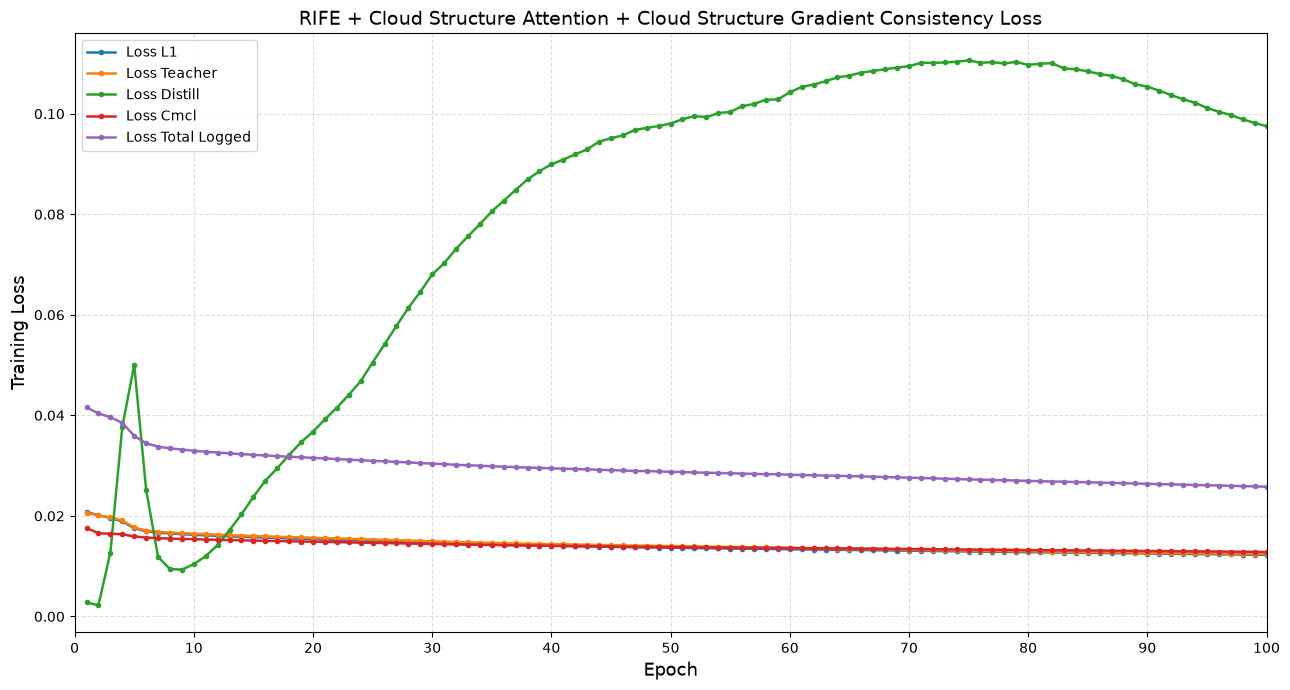

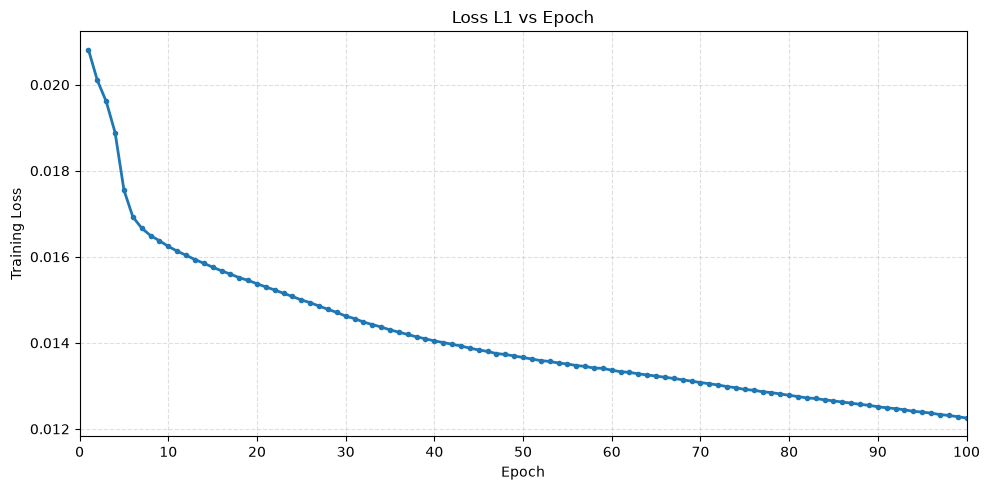

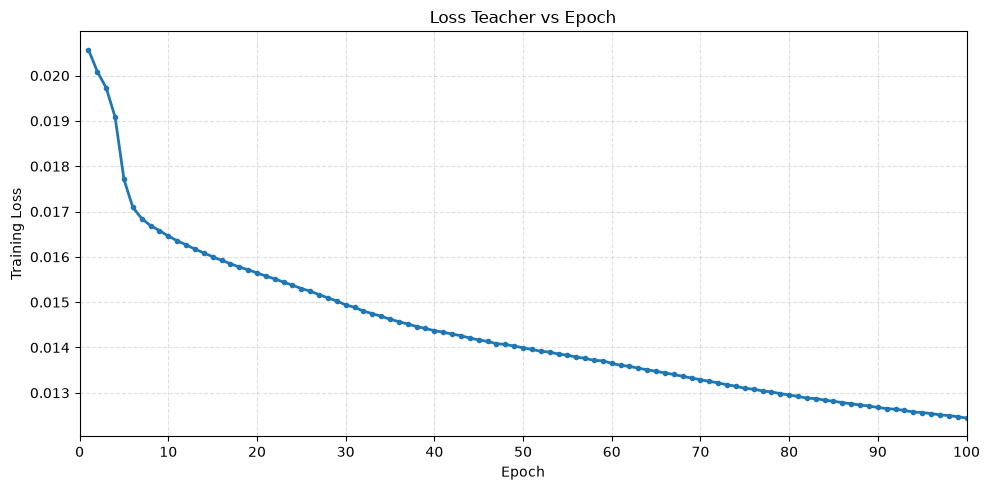

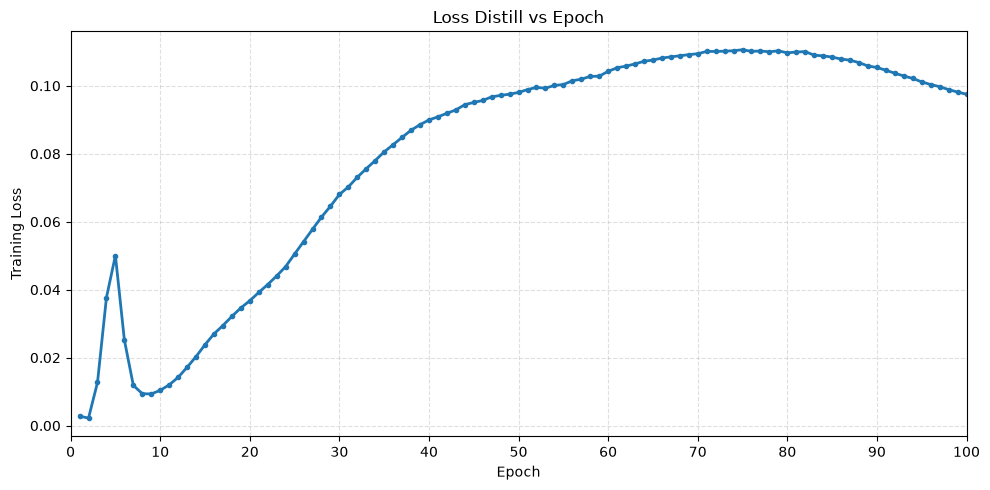

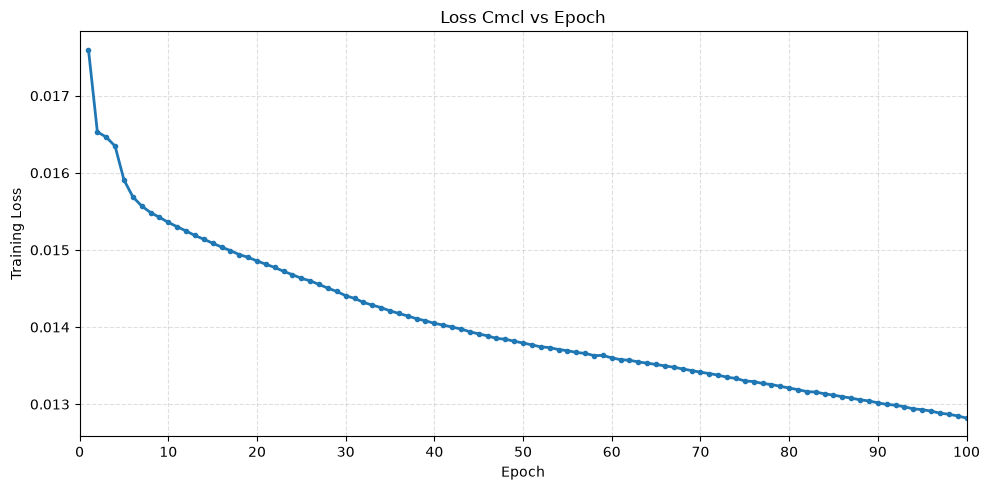

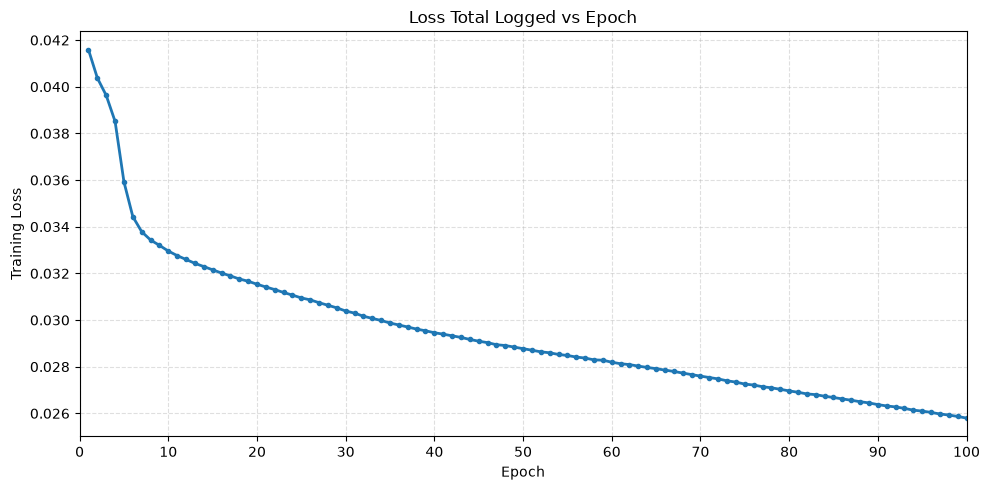


Output folder: /home/kiruthigat.25mcse/Satellite_Frame_Interpolation/checkpoints_NEW/RIFE_CMAM_CMCL_FROM_SCRATCH/training_plots_from_checkpoints


In [12]:

import re
import torch
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(
    "/home/kiruthigat.25mcse/Satellite_Frame_Interpolation"
)

CHECKPOINT_DIR = (
    PROJECT_DIR
    / "checkpoints_NEW"
    / "RIFE_CMAM_CMCL_FROM_SCRATCH"
)

OUTPUT_DIR = CHECKPOINT_DIR / "training_plots_from_checkpoints"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

LOSS_KEYS = [
    "loss_l1",
    "loss_teacher",
    "loss_distill",
    "loss_cmcl",
    "loss_total_logged"
]

def load_checkpoint(path):
    try:
        return torch.load(
            path,
            map_location="cpu",
            weights_only=False
        )
    except TypeError:
        return torch.load(path, map_location="cpu")

def find_loss_values(obj, prefix=""):
    found = {}

    if not isinstance(obj, dict):
        return found

    for key, value in obj.items():
        key_str = str(key).lower()
        full_key = f"{prefix}.{key_str}" if prefix else key_str

        if isinstance(value, dict):
            found.update(find_loss_values(value, full_key))

        elif isinstance(value, (int, float)):
            if "loss" in key_str:
                found[full_key] = float(value)

    return found

rows = []
missing_checkpoints = []
no_loss_checkpoints = []

for epoch in range(1, 101):
    checkpoint_path = CHECKPOINT_DIR / f"epoch_{epoch:03d}.pth"

    if not checkpoint_path.exists():
        missing_checkpoints.append(epoch)
        continue

    checkpoint = load_checkpoint(checkpoint_path)
    losses = find_loss_values(checkpoint)

    row = {"epoch": epoch}

    for column in LOSS_KEYS:
        matches = [
            value for key, value in losses.items()
            if key.split(".")[-1] == column
        ]

        row[column] = matches[0] if matches else float("nan")

    if all(pd.isna(row[column]) for column in LOSS_KEYS):
        no_loss_checkpoints.append(epoch)

    rows.append(row)

    print(
        f"Epoch {epoch:03d}: "
        + ", ".join(
            f"{key}={row[key]:.6g}"
            if pd.notna(row[key]) else f"{key}=NOT STORED"
            for key in LOSS_KEYS
        )
    )

df = pd.DataFrame(rows)

if df.empty:
    raise RuntimeError(
        "No epoch checkpoints were found. Check CHECKPOINT_DIR."
    )

df.to_csv(
    OUTPUT_DIR / "checkpoint_losses_epochs_001_100.csv",
    index=False
)

print("\nCheckpoints found:", len(df))
print("Missing checkpoint epochs:", missing_checkpoints)
print("Checkpoints without saved loss values:", no_loss_checkpoints)

available_columns = [
    column for column in LOSS_KEYS
    if column in df.columns and df[column].notna().any()
]

if not available_columns:
    print(
        "\nNo training losses were saved inside these checkpoints."
        "\nExact historical losses cannot be reconstructed from model "
        "weights alone."
        "\nSee the fallback code below."
    )
else:
    # Combined graph
    plt.figure(figsize=(13, 7))

    for column in available_columns:
        plt.plot(
            df["epoch"],
            df[column],
            marker="o",
            markersize=3,
            linewidth=1.8,
            label=column.replace("_", " ").title()
        )

    plt.xlabel("Epoch", fontsize=13)
    plt.ylabel("Training Loss", fontsize=13)
    plt.title(
        "RIFE + Cloud Structure Attention + "
        "Cloud Structure Gradient Consistency Loss",
        fontsize=14
    )
    plt.xlim(1, 100)
    plt.xticks(range(0, 101, 10))
    plt.grid(True, linestyle="--", alpha=0.4)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / "all_training_losses_epochs_001_100.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.savefig(
        OUTPUT_DIR / "all_training_losses_epochs_001_100.pdf",
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    # Individual graphs
    for column in available_columns:
        plot_df = df.dropna(subset=[column])

        plt.figure(figsize=(10, 5))
        plt.plot(
            plot_df["epoch"],
            plot_df[column],
            marker="o",
            markersize=3,
            linewidth=2
        )
        plt.xlabel("Epoch")
        plt.ylabel("Training Loss")
        plt.title(f"{column.replace('_', ' ').title()} vs Epoch")
        plt.xlim(1, 100)
        plt.xticks(range(0, 101, 10))
        plt.grid(True, linestyle="--", alpha=0.4)
        plt.tight_layout()

        plt.savefig(
            OUTPUT_DIR / f"{column}_epochs_001_100.png",
            dpi=300,
            bbox_inches="tight"
        )
        plt.show()
        plt.close()

print("\nOutput folder:", OUTPUT_DIR)
